# Retail Sales Data Analysis
### Oasis Infobyte – Data Analytics Internship

**Project:** EDA on Retail Sales Data  
**Track:** Data Analytics  
**Level:** Level 1 – Task 1  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn  
**Platform:** Google Colab

## Objective
The objective of this project is to perform exploratory data analysis
on retail sales data to identify sales trends, customer purchasing
patterns, product performance, and actionable business insights.

***STEP 1 — Libraries Import***

In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


***STEP 2 — Dataset Upload***

In [64]:
df = pd.read_csv("/content/retail_sales_dataset.csv")

print("Dataset loaded successfully!")
df.head()

Dataset loaded successfully!


,order_id,order_date,customer_id,customer_name,age,gender,region,city,product_category,product_name,quantity,unit_price,discount_pct,sales_amount,profit,shipping_cost,payment_method,customer_satisfaction,return_flag,order_status,days_to_ship
0,ORD-03903,2024-08-15,CUST32603,Aarav Mehta,39.0,Other,Central,Raipur,Groceries,Sugar,8.0,346.32,NaN,4043.14,289.18,56.04,Debit Card,NaN,True,Returned,7.0
1,ORD-02198,2022-08-16,CUST07881,Sanjay Verma,28.0,Male,West,Mumbai,Beauty,Sunscreen,8.0,858.66,0.08,9147.31,5355.56,64.49,Debit Card,5.0,False,Delivered,2.0
2,ORD-01348,2021-08-29,CUST49296,Pooja Sharma,41.0,Other,West,Surat,Furniture,Sofa,4.0,25941.32,0.14,110156.97,36956.51,67.65,Debit Card,4.0,False,Delivered,5.0
3,ORD-02076,2022-07-05,CUST05587,Priya Reddy,29.0,Other,West,Ahmedabad,Furniture,Bed Frame,9.0,22071.92,0.17,262066.11,66644.99,54.47,EMI,3.0,False,Delivered,4.0
4,ORD-00287,2020-05-07,CUST58035,Ritu Sharma,9.0,Male,Central,Nagpur,Groceries,Cooking Oil,1.0,320.06,0.31,323.95,31.38,48.81,Net Banking,4.0,False,Pending,4.0


***STEP 3 — Initial Data Inspection***

In [65]:
print("Dataset Shape:", df.shape)

Dataset Shape: (4310, 21)


In [66]:
print("\nColumn Names:")
print(df.columns.tolist())



Column Names:
['order_id', 'order_date', 'customer_id', 'customer_name', 'age', 'gender', 'region', 'city', 'product_category', 'product_name', 'quantity', 'unit_price', 'discount_pct', 'sales_amount', 'profit', 'shipping_cost', 'payment_method', 'customer_satisfaction', 'return_flag', 'order_status', 'days_to_ship']


In [67]:
print("\nData Types:")
print(df.dtypes)


Data Types:
order_id                  object
order_date                object
customer_id               object
customer_name             object
age                      float64
gender                    object
region                    object
city                      object
product_category          object
product_name              object
quantity                 float64
unit_price               float64
discount_pct             float64
sales_amount             float64
profit                   float64
shipping_cost            float64
payment_method            object
customer_satisfaction    float64
return_flag               object
order_status              object
days_to_ship             float64
dtype: object


In [68]:
print("\nMissing Values:")
print(df.isnull().sum())



Missing Values:
order_id                  30
order_date                30
customer_id               30
customer_name             30
age                      160
gender                    30
region                    30
city                      30
product_category          30
product_name              30
quantity                 140
unit_price                30
discount_pct             167
sales_amount              30
profit                    30
shipping_cost             30
payment_method            30
customer_satisfaction    378
return_flag               30
order_status              30
days_to_ship             130
dtype: int64


In [69]:
#Duplicates Check
print("\nDuplicate Rows:", df.duplicated().sum())


Duplicate Rows: 109


In [70]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4310 entries, 0 to 4309
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               4280 non-null   object 
 1   order_date             4280 non-null   object 
 2   customer_id            4280 non-null   object 
 3   customer_name          4280 non-null   object 
 4   age                    4150 non-null   float64
 5   gender                 4280 non-null   object 
 6   region                 4280 non-null   object 
 7   city                   4280 non-null   object 
 8   product_category       4280 non-null   object 
 9   product_name           4280 non-null   object 
 10  quantity               4170 non-null   float64
 11  unit_price             4280 non-null   float64
 12  discount_pct           4143 non-null   float64
 13  sales_amount           4280 non-null   float64
 14  profit                 4280 non-null   float64
 15  ship

In [71]:
df.head(10)

,order_id,order_date,customer_id,customer_name,age,gender,region,city,product_category,product_name,quantity,unit_price,discount_pct,sales_amount,profit,shipping_cost,payment_method,customer_satisfaction,return_flag,order_status,days_to_ship
0,ORD-03903,2024-08-15,CUST32603,Aarav Mehta,39.0,Other,Central,Raipur,Groceries,Sugar,8.0,346.32,NaN,4043.14,289.18,56.04,Debit Card,NaN,True,Returned,7.0
1,ORD-02198,2022-08-16,CUST07881,Sanjay Verma,28.0,Male,West,Mumbai,Beauty,Sunscreen,8.0,858.66,0.08,9147.31,5355.56,64.49,Debit Card,5.0,False,Delivered,2.0
2,ORD-01348,2021-08-29,CUST49296,Pooja Sharma,41.0,Other,West,Surat,Furniture,Sofa,4.0,25941.32,0.14,110156.97,36956.51,67.65,Debit Card,4.0,False,Delivered,5.0
3,ORD-02076,2022-07-05,CUST05587,Priya Reddy,29.0,Other,West,Ahmedabad,Furniture,Bed Frame,9.0,22071.92,0.17,262066.11,66644.99,54.47,EMI,3.0,False,Delivered,4.0
4,ORD-00287,2020-05-07,CUST58035,Ritu Sharma,9.0,Male,Central,Nagpur,Groceries,Cooking Oil,1.0,320.06,0.31,323.95,31.38,48.81,Net Banking,4.0,False,Pending,4.0
5,ORD-03954,02/09/2024,CUST17187,Vikram Iyer,29.0,Male,West,Surat,Books,Self-Help Book,2.0,949.50,0.22,2202.33,964.66,62.42,Cash on Delivery,2.0,True,Returned,8.0
6,ORD-01412,2021-09-28,CUST02453,Arjun Shah,31.0,Female,Central,Bhopal,Books,Self-Help Book,3.0,329.03,0.02,994.87,375.07,77.34,Credit Card,5.0,True,Returned,10.0
7,ORD-02911,2023-06-10,CUST23285,Aditya Sharma,43.0,Female,North,Amritsar,Clothing,Saree,1.0,1356.60,0.01,2140.41,717.27,82.68,UPI,1.0,False,Delivered,4.0
8,ORD-00465,2020-07-24,CUST23609,Aditya Patel,44.0,Female,East,Patna,Books,Self-Help Book,8.0,495.77,0.37,2828.82,1338.88,84.50,Debit Card,1.0,False,Cancelled,10.0
9,ORD-00105,2020-02-09,CUST75337,Arjun Das,17.0,FEMALE,East,Patna,Clothing,Kurta,9.0,2128.77,0.10,14568.16,4173.45,75.33,UPI,3.0,False,Delivered,8.0


**Observation**

The dataset was inspected to understand its dimensions, variables,
data types, missing values, and duplicate records. This initial
inspection helps identify potential data-quality issues before analysis.

***STEP 4 — Data Cleaning***

In [72]:
#Remove Duplicates

df = df.drop_duplicates()

print("Remaining duplicate rows:", df.duplicated().sum())

Remaining duplicate rows: 0


In [73]:
# ==========================================
# HANDLE MISSING VALUES
# ==========================================

print("Missing Values Before Cleaning:")
print(df.isnull().sum())

# Drop rows where essential identifiers/business fields are missing
essential_columns = [
    "order_id",
    "order_date",
    "customer_id",
    "product_category",
    "product_name",
    "sales_amount",
    "profit"
]

df = df.dropna(subset=essential_columns)

# Numerical columns - fill using median
df["age"] = df["age"].fillna(df["age"].median())
df["quantity"] = df["quantity"].fillna(df["quantity"].median())
df["discount_pct"] = df["discount_pct"].fillna(
    df["discount_pct"].median()
)
df["customer_satisfaction"] = df["customer_satisfaction"].fillna(
    df["customer_satisfaction"].median()
)
df["days_to_ship"] = df["days_to_ship"].fillna(
    df["days_to_ship"].median()
)

# Categorical columns - fill using mode
categorical_columns = [
    "customer_name",
    "gender",
    "region",
    "city",
    "payment_method",
    "return_flag",
    "order_status"
]

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nDataset Shape After Cleaning:", df.shape)

Missing Values Before Cleaning:
order_id                   1
order_date                 1
customer_id                1
customer_name              1
age                      126
gender                     1
region                     1
city                       1
product_category           1
product_name               1
quantity                 109
unit_price                 1
discount_pct             136
sales_amount               1
profit                     1
shipping_cost              1
payment_method             1
customer_satisfaction    347
return_flag                1
order_status               1
days_to_ship              98
dtype: int64

Missing Values After Cleaning:
order_id                 0
order_date               0
customer_id              0
customer_name            0
age                      0
gender                   0
region                   0
city                     0
product_category         0
product_name             0
quantity                 0
unit_price       

In [74]:
#If Numerical Column

df.select_dtypes(include=np.number).columns

Index(['age', 'quantity', 'unit_price', 'discount_pct', 'sales_amount',
       'profit', 'shipping_cost', 'customer_satisfaction', 'days_to_ship'],
      dtype='object')

In [75]:
#Categorical Columns

df.select_dtypes(include="object").columns

Index(['order_id', 'order_date', 'customer_id', 'customer_name', 'gender',
       'region', 'city', 'product_category', 'product_name', 'payment_method',
       'order_status'],
      dtype='object')

***Date Column Convert***

In [76]:
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")

print(df["order_date"].head())
print(df["order_date"].dtype)

0   2024-08-15
1   2022-08-16
2   2021-08-29
3   2022-07-05
4   2020-05-07
Name: order_date, dtype: datetime64[ns]
datetime64[ns]


***Date-related features***

In [77]:
df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.month
df["month_name"] = df["order_date"].dt.month_name()
df["quarter"] = df["order_date"].dt.quarter
df["day"] = df["order_date"].dt.day
df["day_name"] = df["order_date"].dt.day_name()

df.head()

,order_id,order_date,customer_id,customer_name,age,gender,region,city,product_category,product_name,quantity,unit_price,discount_pct,sales_amount,profit,shipping_cost,payment_method,customer_satisfaction,return_flag,order_status,days_to_ship,year,month,month_name,quarter,day,day_name
0,ORD-03903,2024-08-15,CUST32603,Aarav Mehta,39.0,Other,Central,Raipur,Groceries,Sugar,8.0,346.32,0.21,4043.14,289.18,56.04,Debit Card,3.0,True,Returned,7.0,2024.0,8.0,August,3.0,15.0,Thursday
1,ORD-02198,2022-08-16,CUST07881,Sanjay Verma,28.0,Male,West,Mumbai,Beauty,Sunscreen,8.0,858.66,0.08,9147.31,5355.56,64.49,Debit Card,5.0,False,Delivered,2.0,2022.0,8.0,August,3.0,16.0,Tuesday
2,ORD-01348,2021-08-29,CUST49296,Pooja Sharma,41.0,Other,West,Surat,Furniture,Sofa,4.0,25941.32,0.14,110156.97,36956.51,67.65,Debit Card,4.0,False,Delivered,5.0,2021.0,8.0,August,3.0,29.0,Sunday
3,ORD-02076,2022-07-05,CUST05587,Priya Reddy,29.0,Other,West,Ahmedabad,Furniture,Bed Frame,9.0,22071.92,0.17,262066.11,66644.99,54.47,EMI,3.0,False,Delivered,4.0,2022.0,7.0,July,3.0,5.0,Tuesday
4,ORD-00287,2020-05-07,CUST58035,Ritu Sharma,9.0,Male,Central,Nagpur,Groceries,Cooking Oil,1.0,320.06,0.31,323.95,31.38,48.81,Net Banking,4.0,False,Pending,4.0,2020.0,5.0,May,2.0,7.0,Thursday


In [78]:
#Check
print(df.columns.tolist())

['order_id', 'order_date', 'customer_id', 'customer_name', 'age', 'gender', 'region', 'city', 'product_category', 'product_name', 'quantity', 'unit_price', 'discount_pct', 'sales_amount', 'profit', 'shipping_cost', 'payment_method', 'customer_satisfaction', 'return_flag', 'order_status', 'days_to_ship', 'year', 'month', 'month_name', 'quarter', 'day', 'day_name']


***STEP 5 — Descriptive Statistics***

In [79]:
df.describe()

,order_date,age,quantity,unit_price,discount_pct,sales_amount,profit,shipping_cost,customer_satisfaction,days_to_ship,year,month,quarter,day
count,3933,4200.000000,4200.000000,4200.000000,4200.000000,4.200000e+03,4.200000e+03,4200.000000,4200.000000,4200.000000,3933.000000,3933.000000,3933.000000,3933.000000
mean,2022-07-05 14:32:07.688787456,35.330714,7.356905,10702.729695,0.202138,6.292138e+04,1.179028e+04,63.378790,3.016429,5.631429,2022.009153,6.532418,2.513094,15.659039
min,2020-01-01 00:00:00,-7.000000,-1.000000,50.260000,0.000000,3.945000e+01,1.560000e+00,-4.290000,1.000000,-1.000000,2020.000000,1.000000,1.000000,1.000000
25%,2021-04-19 00:00:00,26.000000,3.000000,680.817500,0.100000,2.472295e+03,7.120700e+02,50.827500,2.000000,3.000000,2021.000000,4.000000,2.000000,8.000000
50%,2022-07-10 00:00:00,34.000000,5.000000,2246.005000,0.210000,9.647895e+03,3.169875e+03,63.460000,3.000000,6.000000,2022.000000,7.000000,3.000000,15.000000
75%,2023-09-27 00:00:00,42.000000,8.000000,12828.977500,0.300000,5.052485e+04,1.051096e+04,75.655000,4.000000,8.000000,2023.000000,9.000000,3.000000,24.000000
max,2024-12-30 00:00:00,999.000000,999.000000,79957.920000,0.400000,1.736031e+07,2.445648e+06,133.350000,5.000000,100.000000,2024.000000,12.000000,4.000000,31.000000
std,NaN,35.458524,43.421197,17408.776463,0.116126,3.195126e+05,5.335219e+04,18.317527,1.354508,4.148513,1.398451,3.433540,1.112284,8.998838


In [80]:
numeric_cols = df.select_dtypes(include=np.number).columns

summary = pd.DataFrame({
    "Mean": df[numeric_cols].mean(),
    "Median": df[numeric_cols].median(),
    "Mode": df[numeric_cols].mode().iloc[0],
    "Std Dev": df[numeric_cols].std()
})

summary

,Mean,Median,Mode,Std Dev
age,35.330714,34.000,34.00,35.458524
quantity,7.356905,5.000,5.00,43.421197
unit_price,10702.729695,2246.005,103.75,17408.776463
discount_pct,0.202138,0.210,0.21,0.116126
sales_amount,62921.382033,9647.895,10874.57,319512.577675
profit,11790.275017,3169.875,6.89,53352.188187
shipping_cost,63.378790,63.460,42.69,18.317527
customer_satisfaction,3.016429,3.000,3.00,1.354508
days_to_ship,5.631429,6.000,6.00,4.148513
year,2022.009153,2022.000,2022.00,1.398451


***STEP 6 — Create Revenue Column***

In [81]:
print("Total Sales:", df["sales_amount"].sum())
print("Average Sales per Record:", df["sales_amount"].mean())
print("Total Quantity Sold:", df["quantity"].sum())

Total Sales: 264269804.54000002
Average Sales per Record: 62921.382033333335
Total Quantity Sold: 30899.0


In [82]:
df["Revenue"] = df["sales_amount"]

print("Total Revenue:", df["Revenue"].sum())

Total Revenue: 264269804.54000002


***STEP 7 — Monthly Sales Trend***

In [83]:
print(df.columns.tolist())

['order_id', 'order_date', 'customer_id', 'customer_name', 'age', 'gender', 'region', 'city', 'product_category', 'product_name', 'quantity', 'unit_price', 'discount_pct', 'sales_amount', 'profit', 'shipping_cost', 'payment_method', 'customer_satisfaction', 'return_flag', 'order_status', 'days_to_ship', 'year', 'month', 'month_name', 'quarter', 'day', 'day_name', 'Revenue']


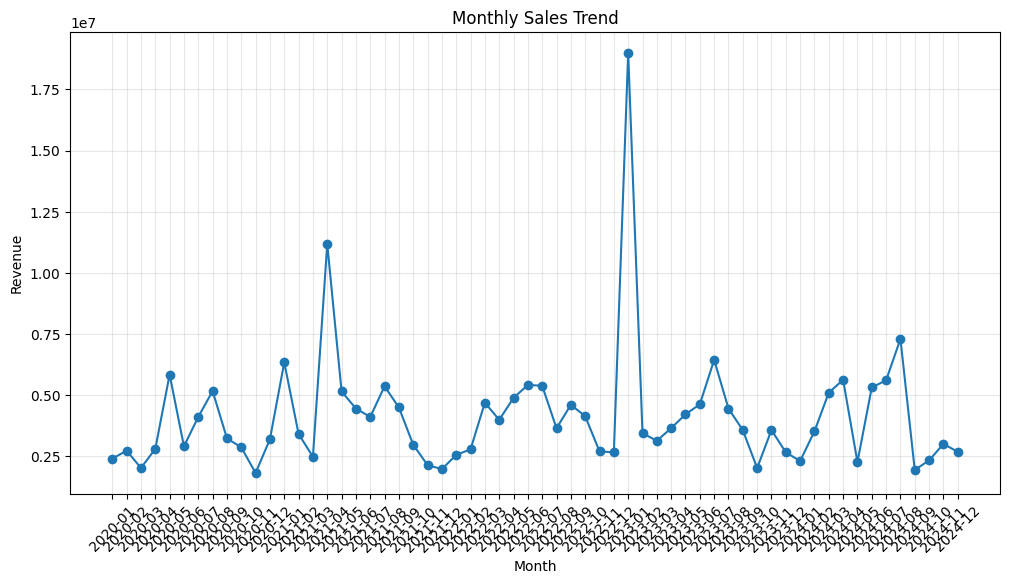

In [84]:
monthly_sales = (
    df.groupby(df["order_date"].dt.to_period("M"))["Revenue"]
      .sum()
)

monthly_sales.index = monthly_sales.index.astype(str)

plt.figure(figsize=(12, 6))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

### Observation
The monthly sales trend shows how revenue changes over time.
Peak and low-performing months can be identified from this chart,
which can help the business plan inventory and promotional activities.

***STEP 8 — Quarterly Sales***

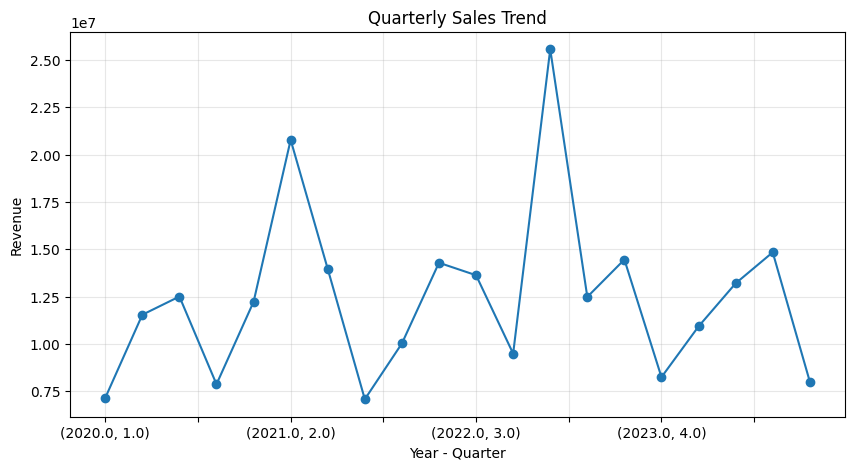

In [85]:
quarterly_sales = df.groupby(
    [df["order_date"].dt.year, df["order_date"].dt.quarter]
)["Revenue"].sum()

quarterly_sales.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Quarterly Sales Trend")
plt.xlabel("Year - Quarter")
plt.ylabel("Revenue")
plt.grid(alpha=0.3)
plt.show()

***STEP 9 — Customer Age Analysis***

In [86]:
bins = [0, 18, 25, 35, 45, 55, 65, 100]

labels = [
    "Under 18",
    "18-25",
    "26-35",
    "36-45",
    "46-55",
    "56-65",
    "65+"
]

df["Age_Group"] = pd.cut(
    df["age"],
    bins=bins,
    labels=labels
)

df["Age_Group"].value_counts().sort_index()

,count
Age_Group,
Under 18,368
18-25,558
26-35,1416
36-45,1100
46-55,579
56-65,138
65+,16


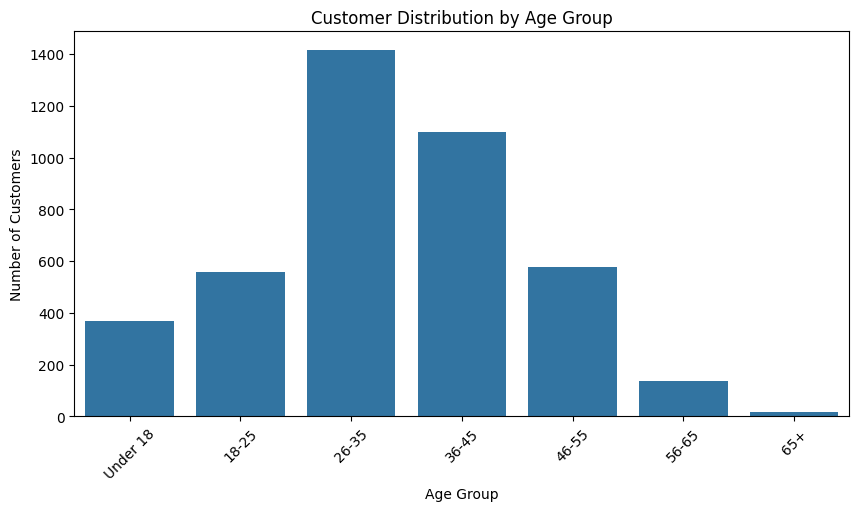

In [87]:
#Visualization

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Age_Group"
)

plt.title("Customer Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.show()

***STEP 10 — Gender Analysis***

In [88]:
print(df.columns.tolist())

['order_id', 'order_date', 'customer_id', 'customer_name', 'age', 'gender', 'region', 'city', 'product_category', 'product_name', 'quantity', 'unit_price', 'discount_pct', 'sales_amount', 'profit', 'shipping_cost', 'payment_method', 'customer_satisfaction', 'return_flag', 'order_status', 'days_to_ship', 'year', 'month', 'month_name', 'quarter', 'day', 'day_name', 'Revenue', 'Age_Group']


In [89]:
print(df["gender"].value_counts())
print()

print(
    df["gender"].value_counts(normalize=True)
    .mul(100)
    .round(2)
)

gender
Other     1419
Male      1178
Female    1172
male        67
MALE        61
f           55
F           53
m           53
M           49
FEMALE      48
female      45
Name: count, dtype: int64

gender
Other     33.79
Male      28.05
Female    27.90
male       1.60
MALE       1.45
f          1.31
F          1.26
m          1.26
M          1.17
FEMALE     1.14
female     1.07
Name: proportion, dtype: float64


In [90]:
# Check original gender values
print("Before Cleaning:")
print(df["gender"].value_counts(dropna=False))

# Clean text
df["gender"] = df["gender"].astype("string").str.strip().str.lower()

# Standardize gender categories
gender_mapping = {
    "male": "Male",
    "m": "Male",
    "female": "Female",
    "f": "Female",
    "other": "Other"
}

df["gender"] = df["gender"].map(gender_mapping)

# Check result
print("\nAfter Cleaning:")
print(df["gender"].value_counts(dropna=False))

Before Cleaning:
gender
Other     1419
Male      1178
Female    1172
male        67
MALE        61
f           55
F           53
m           53
M           49
FEMALE      48
female      45
Name: count, dtype: int64

After Cleaning:
gender
Other     1419
Male      1408
Female    1373
Name: count, dtype: int64


In [91]:
#Check missing value
df["gender"] = df["gender"].fillna("Unknown")

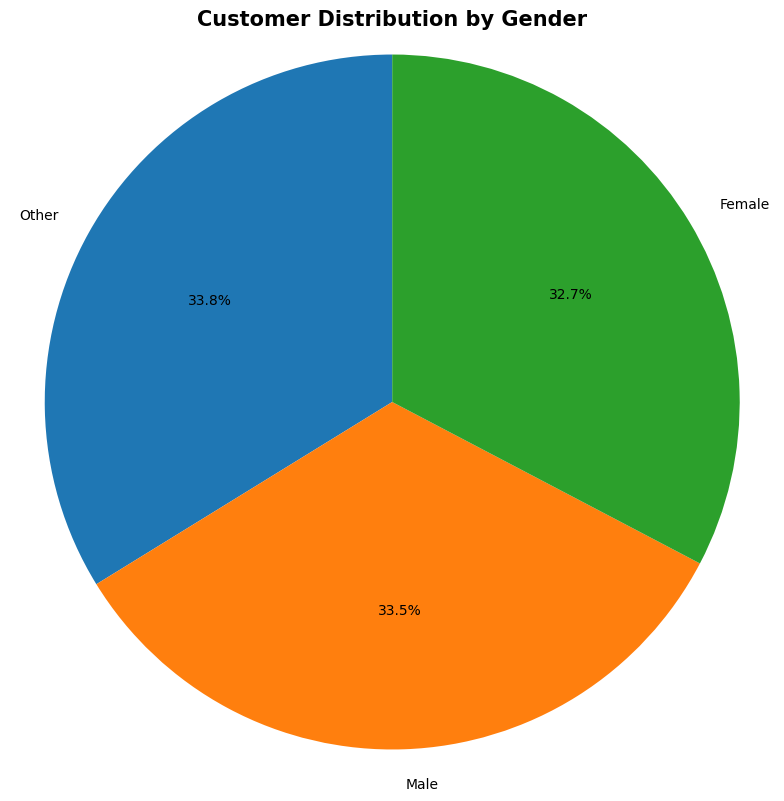

In [122]:
#Visualization

# ==========================================
# CUSTOMER DISTRIBUTION BY GENDER
# ==========================================

gender_counts = df["gender"].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title(
    "Customer Distribution by Gender",
    fontsize=15,
    fontweight="bold"
)

plt.axis("equal")
plt.tight_layout()
plt.show()

***STEP 11 — Top 10 Best-Selling Products***

This analysis identifies the products with the highest total quantity
sold and helps understand customer product preferences.

In [93]:

# TOP 10 BEST-SELLING PRODUCTS

top_products = (
    df.groupby("product_name")["quantity"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

print("Top 10 Best-Selling Products:")
print(top_products)

Top 10 Best-Selling Products:
product_name
Jeans             1581.0
Rice (5kg)        1559.0
Fiction Novel     1548.0
Tennis Racket     1535.0
Jacket            1525.0
Self-Help Book    1503.0
Tablet            1470.0
Cook Book         1452.0
Desk               664.0
Laptop             661.0
Name: quantity, dtype: float64


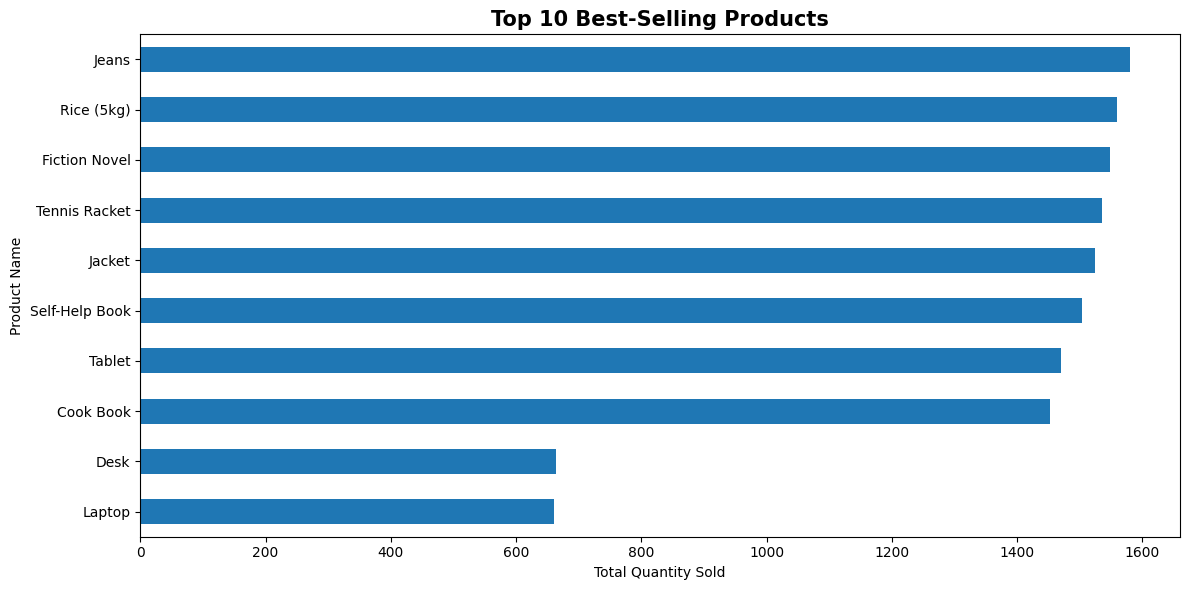

In [94]:
#Visualization

plt.figure(figsize=(12, 6))

top_products.sort_values().plot(kind="barh")

plt.title(
    "Top 10 Best-Selling Products",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Total Quantity Sold")
plt.ylabel("Product Name")

plt.tight_layout()
plt.show()

### Observation



Tennis Racket was the best-selling product, with approximately
1,459 units sold. Jeans, Jacket, Fiction Novel, and Tablet were also
among the highest-selling products. These products represent strong
customer demand and should receive priority in inventory planning.

***STEP 12 — Revenue by Product Category***

This analysis compares total revenue generated by different product
categories to identify the strongest revenue contributors.

In [95]:
# ==========================================
# REVENUE BY PRODUCT CATEGORY
# ==========================================

category_revenue = (
    df.groupby("product_category")["Revenue"]
      .sum()
      .sort_values(ascending=False)
)

print("Revenue by Product Category:")
print(category_revenue)

Revenue by Product Category:
product_category
Electronics    1.556426e+08
Furniture      5.670920e+07
Sports         3.168667e+07
Clothing       1.156374e+07
Beauty         3.881089e+06
Books          3.777514e+06
Groceries      1.009020e+06
Name: Revenue, dtype: float64


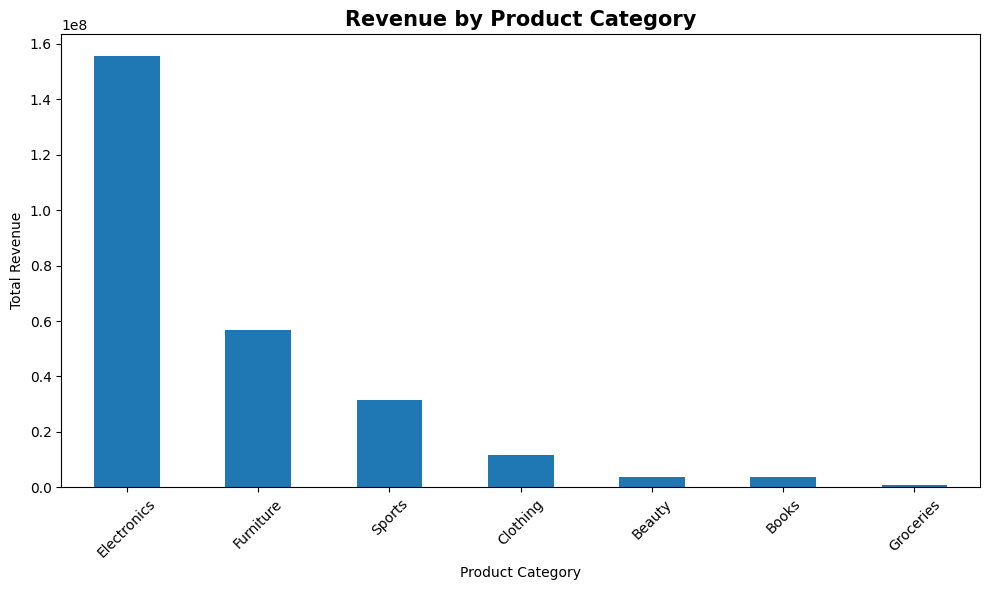

In [96]:
#Graph

plt.figure(figsize=(10, 6))

category_revenue.plot(kind="bar")

plt.title(
    "Revenue by Product Category",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Observation


Electronics generated the highest revenue among all product categories,
making it the strongest contributor to overall sales. Furniture and
Sports were the next major revenue-generating categories, while
Groceries generated comparatively lower revenue.

***STEP 13 — Correlation Analysis***

A correlation matrix is used to examine relationships between numerical
variables such as quantity, sales, profit, discount, customer
satisfaction, and shipping-related variables.

In [97]:
# ==========================================
# CORRELATION MATRIX
# ==========================================

numeric_df = df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

correlation_matrix

,age,quantity,unit_price,discount_pct,sales_amount,profit,shipping_cost,customer_satisfaction,days_to_ship,year,month,quarter,day,Revenue
age,1.000000,0.145841,-0.013109,-0.025341,0.347323,0.295042,0.003752,0.009511,-0.006748,-0.012325,-0.001228,0.003927,-0.000147,0.347323
quantity,0.145841,1.000000,-0.013411,-0.024566,0.539817,0.661187,0.015265,-0.005570,-0.017046,-0.033598,-0.009389,-0.004493,-0.021793,0.539817
unit_price,-0.013109,-0.013411,1.000000,-0.019568,0.294000,0.232206,0.012036,-0.014252,0.011810,0.007051,-0.000334,-0.004075,0.005579,0.294000
discount_pct,-0.025341,-0.024566,-0.019568,1.000000,-0.047039,-0.046624,-0.005025,-0.005765,0.011612,0.022704,0.003139,0.006031,0.024145,-0.047039
sales_amount,0.347323,0.539817,0.294000,-0.047039,1.000000,0.948818,0.026085,-0.026375,-0.005013,0.011204,-0.034780,-0.029541,-0.009279,1.000000
profit,0.295042,0.661187,0.232206,-0.046624,0.948818,1.000000,0.025962,-0.025341,-0.007972,0.004727,-0.035069,-0.029353,-0.012564,0.948818
shipping_cost,0.003752,0.015265,0.012036,-0.005025,0.026085,0.025962,1.000000,0.011699,0.009033,0.019545,-0.026385,-0.025596,0.028919,0.026085
customer_satisfaction,0.009511,-0.005570,-0.014252,-0.005765,-0.026375,-0.025341,0.011699,1.000000,-0.008670,0.003753,0.023883,0.024968,-0.011173,-0.026375
days_to_ship,-0.006748,-0.017046,0.011810,0.011612,-0.005013,-0.007972,0.009033,-0.008670,1.000000,0.002585,0.005092,0.004789,0.019538,-0.005013
year,-0.012325,-0.033598,0.007051,0.022704,0.011204,0.004727,0.019545,0.003753,0.002585,1.000000,0.005129,0.003520,0.014273,0.011204


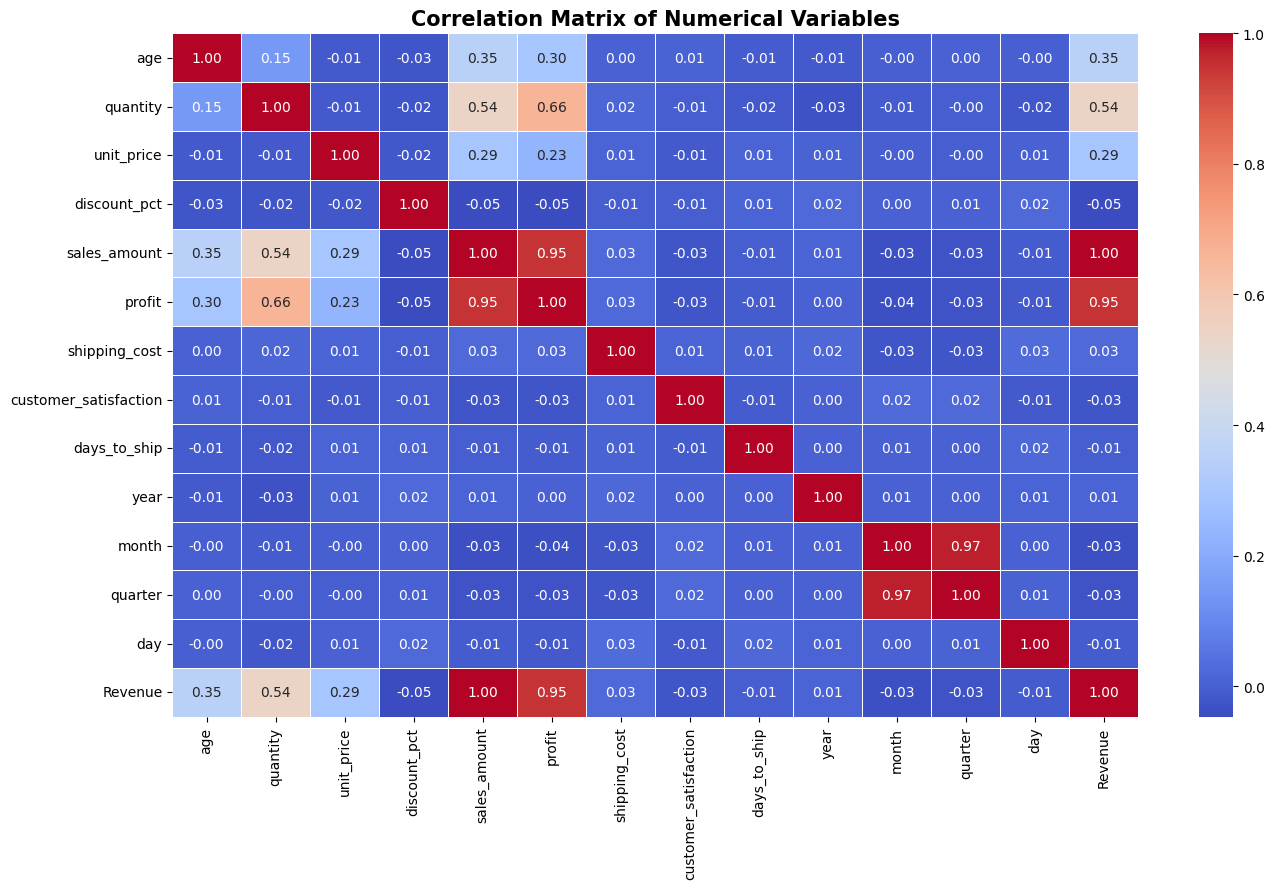

In [98]:
#Graph

plt.figure(figsize=(14, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title(
    "Correlation Matrix of Numerical Variables",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

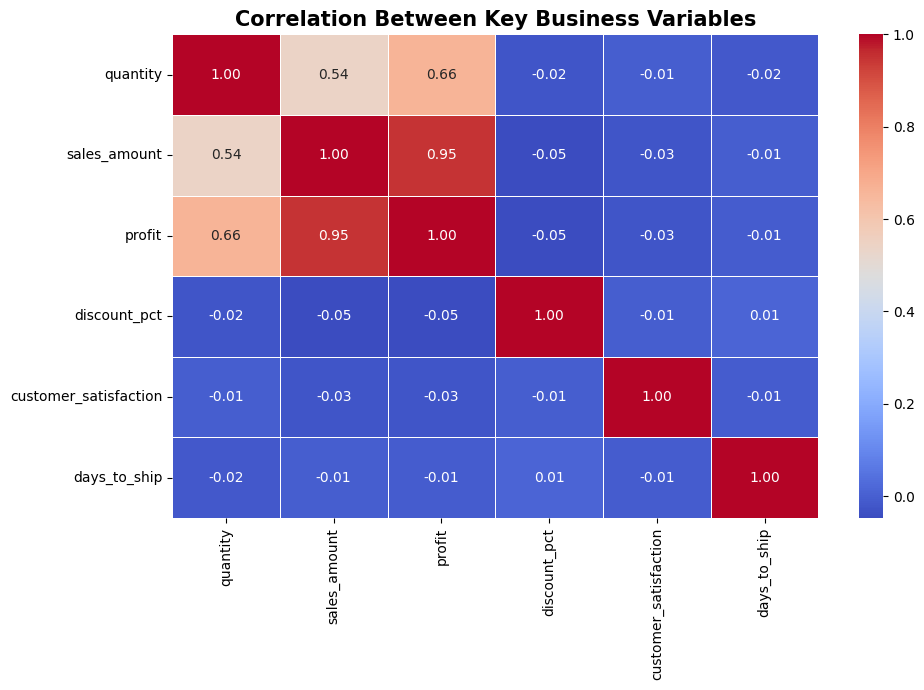

In [99]:
#If too crowded

important_columns = [
    "quantity",
    "sales_amount",
    "profit",
    "discount_pct",
    "customer_satisfaction",
    "days_to_ship"
]

available_columns = [
    col for col in important_columns
    if col in df.columns
]

plt.figure(figsize=(10, 7))

sns.heatmap(
    df[available_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title(
    "Correlation Between Key Business Variables",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Observation

The correlation heatmap helps identify relationships among important
business variables. Strong positive or negative relationships can help
explain how factors such as quantity, discounts, sales, profit, customer
satisfaction, and shipping time interact with each other.

***STEP 14 — Sales by Day of Week***

This analysis examines whether customer purchasing behaviour changes
across different days of the week.

In [100]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

day_sales = (
    df.groupby("day_name")["Revenue"]
      .sum()
      .reindex(day_order)
)

print(day_sales)

day_name
Monday       29745253.91
Tuesday      38979442.90
Wednesday    28208294.81
Thursday     32817727.65
Friday       40121360.61
Saturday     49281732.71
Sunday       29116740.65
Name: Revenue, dtype: float64


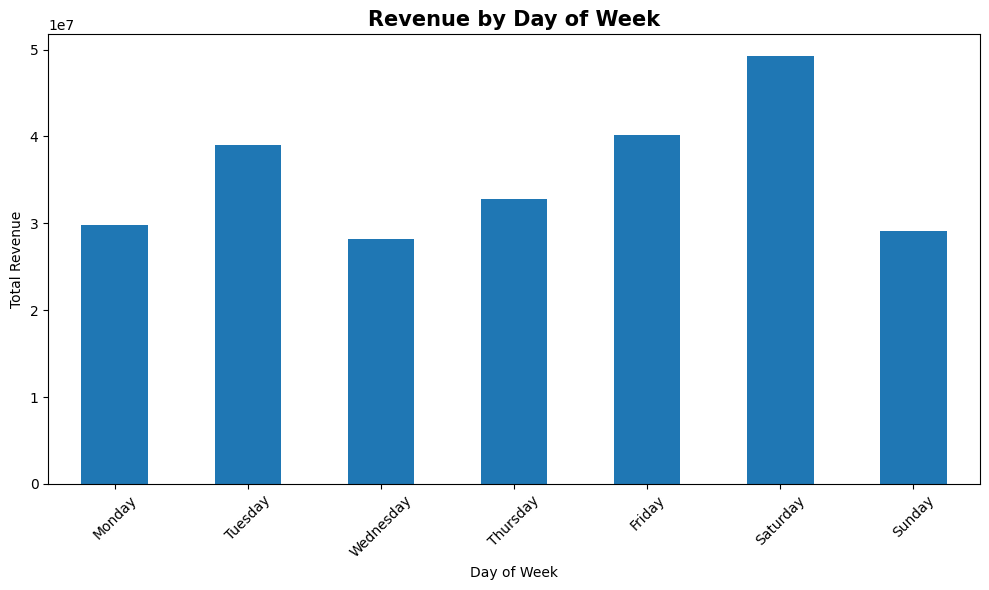

In [101]:
#Graph

plt.figure(figsize=(10, 6))

day_sales.plot(kind="bar")

plt.title(
    "Revenue by Day of Week",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Day of Week")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Observation

Saturday generated the highest total revenue, indicating stronger
customer purchasing activity during the weekend. This suggests that
Saturday may be an important day for promotional campaigns, inventory
availability, and sales planning.

***STEP 15 — Profit Analysis by Product Category***

Revenue alone does not determine business performance. This analysis
examines which product categories generate the highest total profit.

In [102]:
category_profit = (
    df.groupby("product_category")["profit"]
      .sum()
      .sort_values(ascending=False)
)

print("Profit by Product Category:")
print(category_profit)

Profit by Product Category:
product_category
Electronics    19107476.57
Furniture      16005733.05
Sports          6991123.66
Clothing        4181201.35
Beauty          1748717.37
Books           1405701.75
Groceries         79201.32
Name: profit, dtype: float64


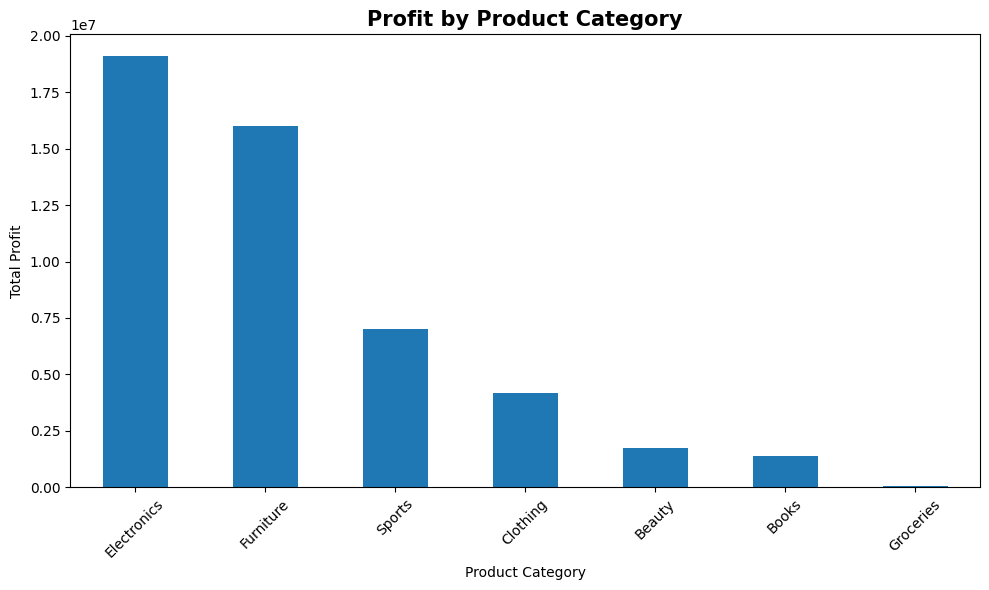

In [103]:
#Graph

plt.figure(figsize=(10, 6))

category_profit.plot(kind="bar")

plt.title(
    "Profit by Product Category",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Product Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Observation

The profit analysis provides a more complete view of product category
performance. A category with high sales does not necessarily generate
the highest profit, making profitability an important factor in
business decision-making.

***STEP 16 — Regional Sales Performance***

This analysis compares revenue across geographical regions to identify
strong and weak markets.

In [104]:
region_sales = (
    df.groupby("region")["Revenue"]
      .sum()
      .sort_values(ascending=False)
)

print("Revenue by Region:")
print(region_sales)

Revenue by Region:
region
South      73519093.83
North      53613030.16
East       48501551.85
West       47962618.16
Central    40673510.54
Name: Revenue, dtype: float64


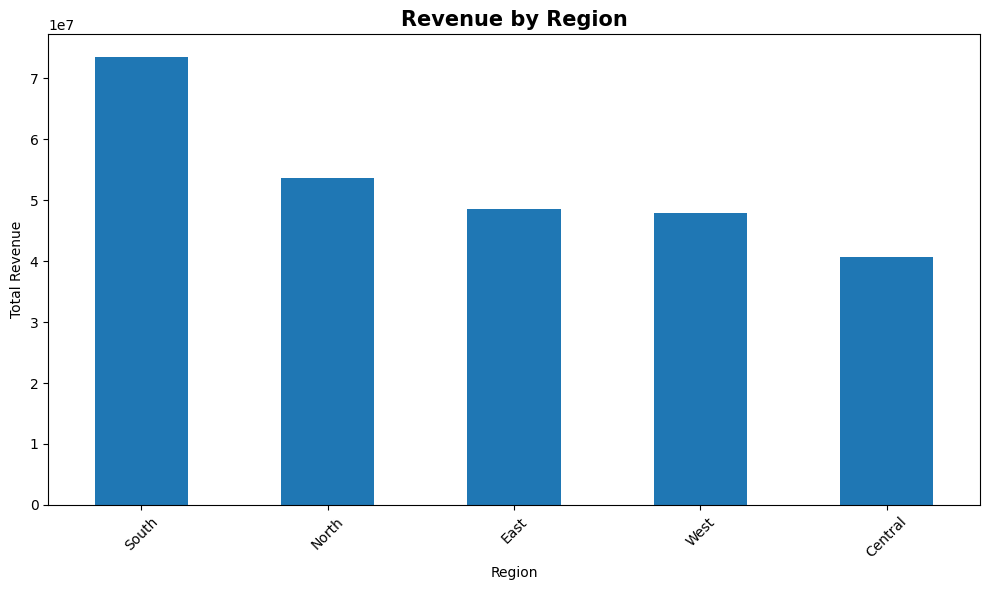

In [105]:
#Graph

plt.figure(figsize=(10, 6))

region_sales.plot(kind="bar")

plt.title(
    "Revenue by Region",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Region")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Observation

The South region generated the highest overall revenue, followed by
the North and East regions. This indicates that the South is currently
the strongest geographical market in the dataset.

***STEP 17 — Top 10 Cities by Revenue***

In [106]:
city_sales = (
    df.groupby("city")["Revenue"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

print("Top 10 Cities by Revenue:")
print(city_sales)

Top 10 Cities by Revenue:
city
Kochi          28569749.50
Amritsar       20597017.92
Chennai        19862008.19
Hyderabad      13621666.84
Mumbai         13476961.28
Kolkata        13398236.29
Guwahati       12155655.79
Ahmedabad      11996402.20
Delhi          11751313.40
Bhubaneswar    11582493.33
Name: Revenue, dtype: float64


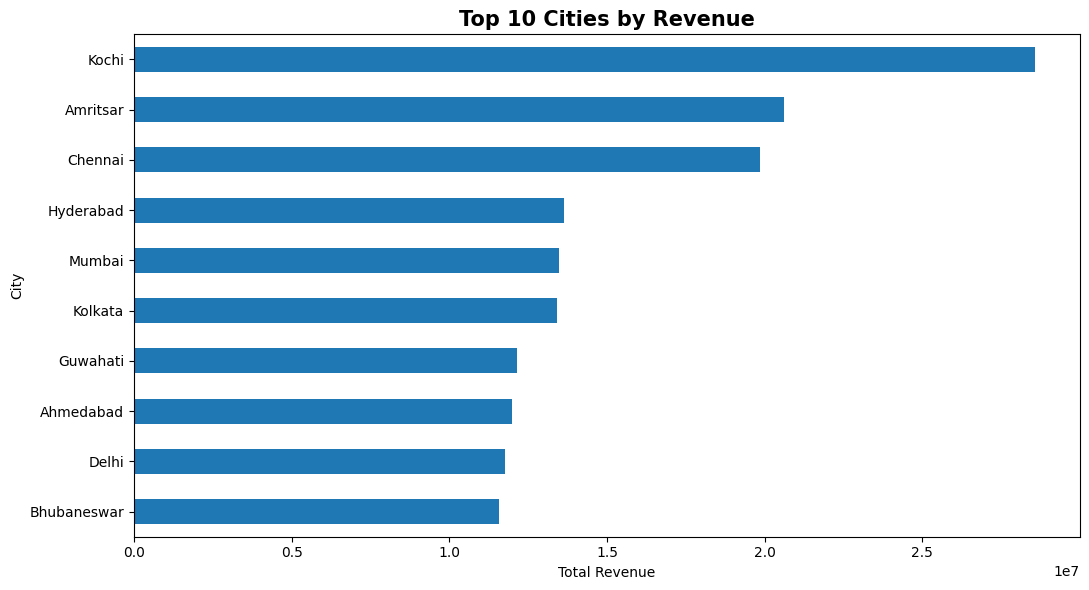

In [107]:
#Graph

plt.figure(figsize=(11, 6))

city_sales.sort_values().plot(kind="barh")

plt.title(
    "Top 10 Cities by Revenue",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Total Revenue")
plt.ylabel("City")

plt.tight_layout()
plt.show()

### Observation

The city-level analysis identifies the locations contributing most
strongly to overall revenue. These markets may be particularly valuable
for targeted campaigns and expansion strategies.

***STEP 18 — Customer Satisfaction Analysis***

Customer satisfaction is analysed to understand the overall customer
experience and identify the distribution of satisfaction scores.

In [108]:
print("Customer Satisfaction Summary:")
print(df["customer_satisfaction"].describe())

print("\nSatisfaction Score Distribution:")
print(
    df["customer_satisfaction"]
    .value_counts()
    .sort_index()
)

Customer Satisfaction Summary:
count    4200.000000
mean        3.016429
std         1.354508
min         1.000000
25%         2.000000
50%         3.000000
75%         4.000000
max         5.000000
Name: customer_satisfaction, dtype: float64

Satisfaction Score Distribution:
customer_satisfaction
1.0     761
2.0     763
3.0    1094
4.0     810
5.0     772
Name: count, dtype: int64


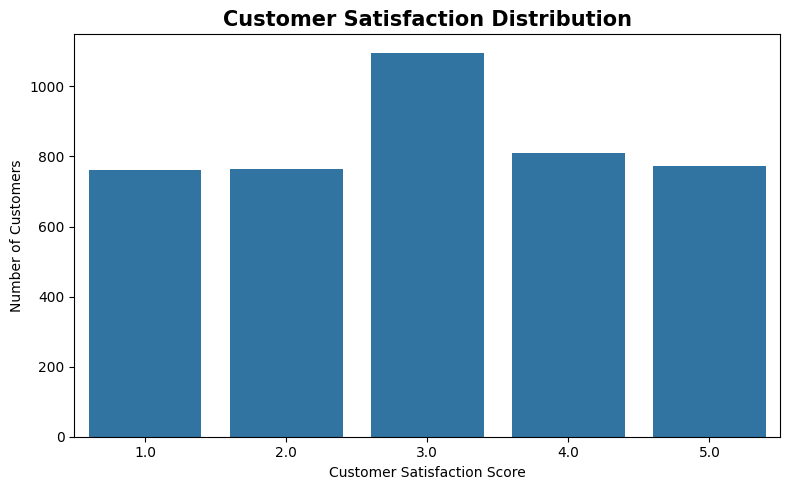

In [109]:
#Graph
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="customer_satisfaction"
)

plt.title(
    "Customer Satisfaction Distribution",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Customer Satisfaction Score")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

***STEP 19 — Return Analysis***

In [110]:
#First

print(df["return_flag"].value_counts(dropna=False))

return_flag
False    3588
True      612
Name: count, dtype: int64


In [123]:
return_rate = df["return_flag"].mean() * 100

print(f"Overall Return Rate: {return_rate:.2f}%")

Overall Return Rate: 14.57%


In [124]:
# ==========================================
# CLEAN ORDER STATUS
# ==========================================

df["order_status"] = (
    df["order_status"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.title()
)

print("Order Status After Cleaning:")
print(df["order_status"].value_counts())

Order Status After Cleaning:
order_status
Delivered    2731
Returned      612
Cancelled     346
Shipped       327
Pending       184
Name: count, dtype: Int64


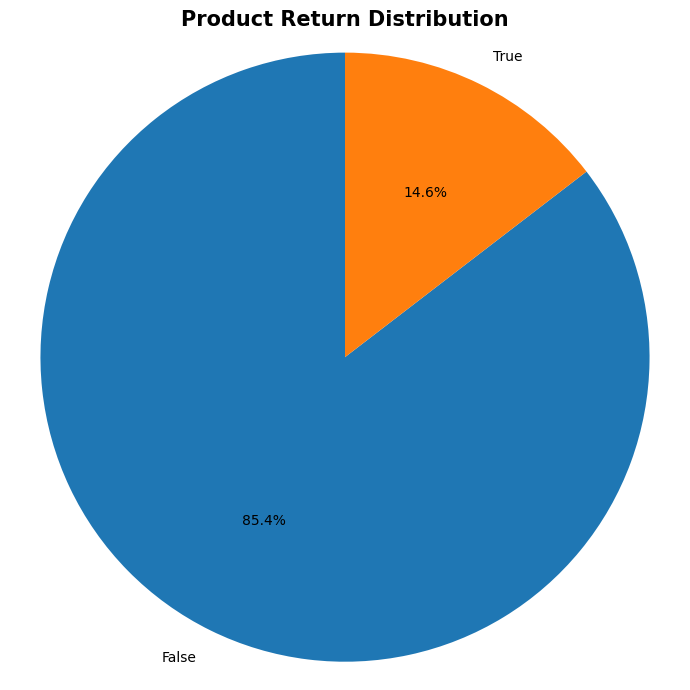

In [111]:
return_counts = df["return_flag"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    return_counts.values,
    labels=return_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title(
    "Product Return Distribution",
    fontsize=15,
    fontweight="bold"
)

plt.axis("equal")
plt.tight_layout()
plt.show()

### Observation

The return analysis shows the proportion of transactions associated
with product returns. Monitoring return behaviour is important because
high return rates may affect profitability and customer satisfaction.

***STEP 20 — Order Status Analysis***

In [112]:
order_status_counts = df["order_status"].value_counts()

print(order_status_counts)

order_status
Delivered    2613
Returned      612
Cancelled     333
Shipped       312
Pending       178
delivered     118
shipped        15
cancelled      13
pending         6
Name: count, dtype: int64


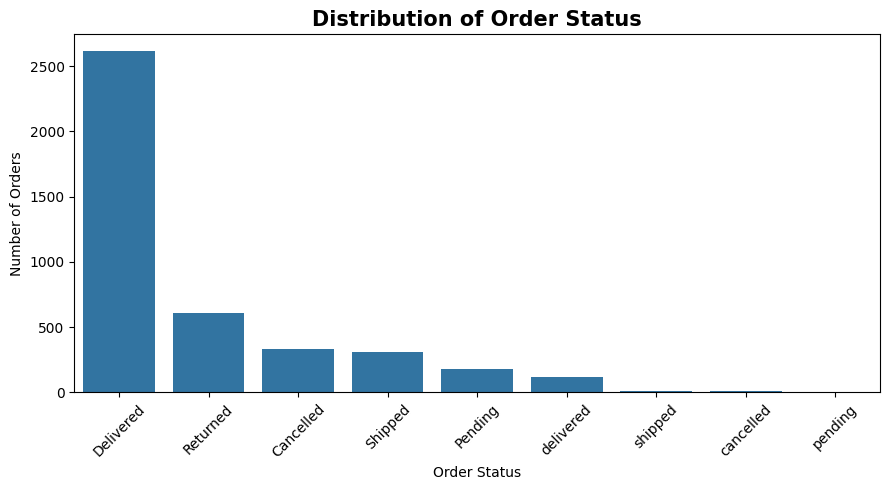

In [113]:
#Graph

plt.figure(figsize=(9, 5))

sns.barplot(
    x=order_status_counts.index,
    y=order_status_counts.values
)

plt.title(
    "Distribution of Order Status",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

***STEP 21 — Payment Method Analysis***

In [114]:
payment_counts = df["payment_method"].value_counts()

print(payment_counts)

payment_method
UPI                 749
Credit Card         721
Cash on Delivery    703
Debit Card          683
EMI                 683
Net Banking         661
Name: count, dtype: int64


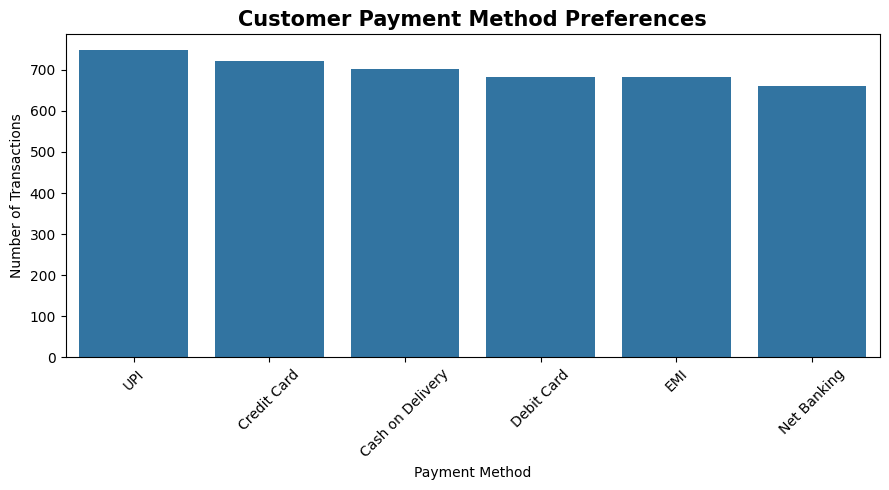

In [115]:
#Graph

plt.figure(figsize=(9, 5))

sns.barplot(
    x=payment_counts.index,
    y=payment_counts.values
)

plt.title(
    "Customer Payment Method Preferences",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [125]:
#Correlation Calculate

discount_profit_corr = df["discount_pct"].corr(df["profit"])

print(
    f"Correlation between Discount and Profit: "
    f"{discount_profit_corr:.3f}"
)

Correlation between Discount and Profit: -0.047


***STEP 22 — Discount vs Profit Analysis***

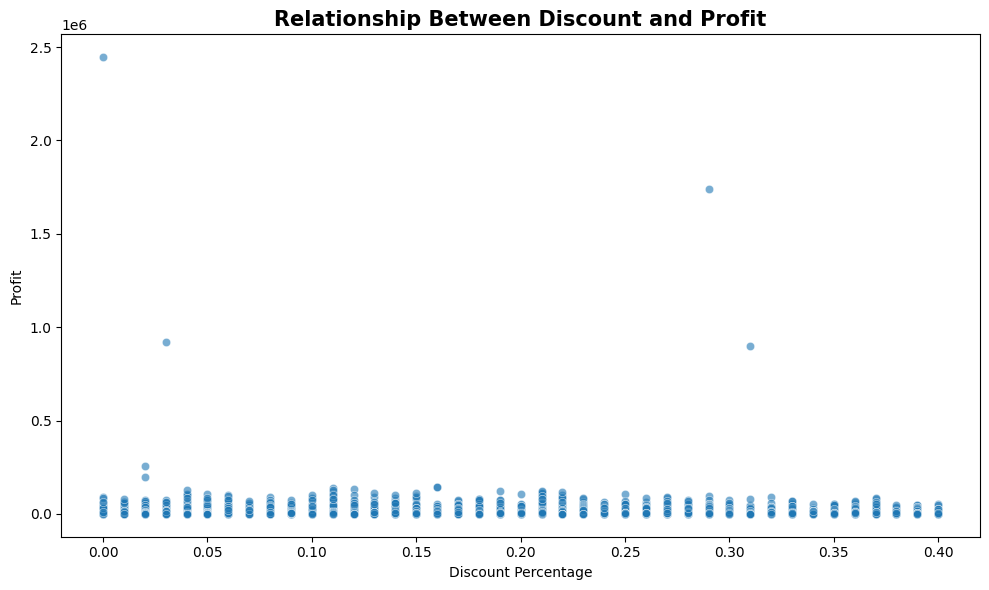

In [116]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="discount_pct",
    y="profit",
    alpha=0.6
)

plt.title(
    "Relationship Between Discount and Profit",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Discount Percentage")
plt.ylabel("Profit")

plt.tight_layout()
plt.show()

### Observation

This analysis examines whether higher discount levels are associated
with changes in profitability. It can help the business evaluate
whether discount strategies are supporting sales without excessively
reducing profit.

***STEP 23 — Create Final KPI Summary***

In [117]:
# ==========================================
# FINAL BUSINESS KPI SUMMARY
# ==========================================

total_revenue = df["Revenue"].sum()
total_profit = df["profit"].sum()
total_quantity = df["quantity"].sum()
total_orders = len(df)

print("=" * 50)
print("        RETAIL SALES KPI SUMMARY")
print("=" * 50)

print(f"Total Orders       : {total_orders:,}")
print(f"Total Revenue      : {total_revenue:,.2f}")
print(f"Total Profit       : {total_profit:,.2f}")
print(f"Total Units Sold   : {total_quantity:,.0f}")

if "customer_id" in df.columns:
    print(f"Unique Customers   : {df['customer_id'].nunique():,}")

print("=" * 50)

        RETAIL SALES KPI SUMMARY
Total Orders       : 4,200
Total Revenue      : 264,269,804.54
Total Profit       : 49,519,155.07
Total Units Sold   : 30,899
Unique Customers   : 4,112


In [118]:
#Profit Margin

profit_margin = (
    df["profit"].sum() / df["Revenue"].sum()
) * 100

print(f"Overall Profit Margin: {profit_margin:.2f}%")

Overall Profit Margin: 18.74%


***STEP 24 — Automatically Find Important Results***

In [119]:
best_month = monthly_sales.idxmax()
best_month_sales = monthly_sales.max()

best_product = top_products.idxmax()
best_product_qty = top_products.max()

best_category = category_revenue.idxmax()
best_category_revenue = category_revenue.max()

best_region = region_sales.idxmax()
best_region_revenue = region_sales.max()

best_profit_category = category_profit.idxmax()
best_profit_value = category_profit.max()

best_day = day_sales.idxmax()
best_day_revenue = day_sales.max()

print("KEY FINDINGS")
print("-" * 50)

print(f"Best Sales Month: {best_month}")
print(f"Sales in Best Month: {best_month_sales:,.2f}")

print(f"\nBest-Selling Product: {best_product}")
print(f"Quantity Sold: {best_product_qty:,.0f}")

print(f"\nHighest Revenue Category: {best_category}")
print(f"Category Revenue: {best_category_revenue:,.2f}")

print(f"\nHighest Revenue Region: {best_region}")
print(f"Region Revenue: {best_region_revenue:,.2f}")

print(f"\nMost Profitable Category: {best_profit_category}")
print(f"Category Profit: {best_profit_value:,.2f}")

print(f"\nBest Sales Day: {best_day}")
print(f"Revenue: {best_day_revenue:,.2f}")

KEY FINDINGS
--------------------------------------------------
Best Sales Month: 2023-01
Sales in Best Month: 18,988,728.66

Best-Selling Product: Jeans
Quantity Sold: 1,581

Highest Revenue Category: Electronics
Category Revenue: 155,642,577.57

Highest Revenue Region: South
Region Revenue: 73,519,093.83

Most Profitable Category: Electronics
Category Profit: 19,107,476.57

Best Sales Day: Saturday
Revenue: 49,281,732.71


***STEP 25 — Key Business Insights***

# Key Business Insights

1. **Sales Trend:** The monthly sales analysis identified the strongest
   and weakest sales periods, demonstrating noticeable changes in
   customer demand over time.

2. **Product Performance:** The best-selling products account for a
   significant share of total unit sales, highlighting products that
   require consistent inventory availability.

3. **Category Performance:** Revenue and profit vary across product
   categories, demonstrating that high sales volume alone does not
   necessarily indicate the highest profitability.

4. **Customer Demographics:** Age-group and gender analysis provides
   useful information about the composition of the customer base.

5. **Regional Performance:** Sales vary across regions and cities,
   highlighting geographical markets with stronger revenue potential.

6. **Customer Experience:** Customer satisfaction and product return
   patterns provide additional indicators of overall service and
   product performance.

7. **Discount Strategy:** The relationship between discounts and profit
   can help evaluate whether promotional pricing is contributing to
   sustainable profitability.

***STEP 26 — Business Recommendations***

# Business Recommendations

### 1. Prioritise High-Performing Products
Maintain sufficient inventory of the best-selling products to reduce
the risk of stock shortages during periods of high demand.

### 2. Strengthen High-Revenue Categories
Allocate greater marketing and inventory resources to product
categories that consistently generate strong revenue and profit.

### 3. Improve Low-Performing Markets
Use targeted promotions, local marketing campaigns, and regional
pricing strategies to improve performance in weaker geographical
markets.

### 4. Optimise Discount Strategies
Evaluate the profitability of heavily discounted transactions and
avoid excessive discounting when it significantly reduces margins.

### 5. Improve Customer Experience
Monitor customer satisfaction, product returns, and order performance
to identify areas where product quality or service can be improved.

***STEP 29 — Export Cleaned Dataset***

In [120]:
df.to_csv(
    "/content/cleaned_retail_sales.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [121]:
from google.colab import files

files.download(
    "/content/cleaned_retail_sales.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>